# PaySim Dataset Exploration

This notebook performs descriptive, reproducible exploration of the local PaySim CSV. It does **not** train or evaluate a model. Results are separated into official dataset facts, project calculations, and modelling constraints.

## 1. Dataset provenance and official warnings

**Official dataset facts:** PaySim is a synthetic mobile-money simulator. The Kaggle dataset represents approximately one month of activity, and one `step` represents one hour. The dataset documentation states that detected fraud transactions are cancelled.

> **Modelling constraint:** `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`, and every feature derived from them are **analysis only and must not be used as predictive features**.

Sources: [Kaggle dataset documentation](https://www.kaggle.com/datasets/ealaxi/paysim1/data) and [PaySim paper](https://www.msc-les.org/proceedings/emss/2016/EMSS2016_249.pdf).

## 2. Imports and configuration

The raw file is processed in 500,000-row chunks. Only compact aggregates and the numeric arrays required for exact medians and plots are retained.

In [1]:
from collections import Counter
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.paysim_eda import (
    ANALYSIS_ONLY_BALANCE_COLUMNS,
    EXPECTED_COLUMNS,
    balance_discrepancies,
    iter_paysim_chunks,
    simulated_day,
    validate_schema,
)

CSV_FILES = sorted((PROJECT_ROOT / "data" / "raw").glob("*.csv"))
if len(CSV_FILES) != 1:
    raise RuntimeError(f"Expected one raw PaySim CSV, found {len(CSV_FILES)}.")
CSV_PATH = CSV_FILES[0]
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CHUNK_SIZE = 500_000
TYPE_ORDER = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})

## 3. File and schema validation

In [2]:
columns = validate_schema(CSV_PATH)
preview = pd.read_csv(CSV_PATH, nrows=5)
file_details = pd.Series({
    "filename": CSV_PATH.name,
    "size_bytes": CSV_PATH.stat().st_size,
    "size_mib": round(CSV_PATH.stat().st_size / 1024**2, 2),
    "columns": len(columns),
})
display(file_details.to_frame("value"))
display(preview)
display(preview.dtypes.rename("dtype").to_frame())

,value
filename,PS_20174392719_1491204439457_log.csv
size_bytes,493534783
size_mib,470.67
columns,11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


,dtype
step,int64
type,object
amount,float64
nameOrig,object
oldbalanceOrg,float64
newbalanceOrig,float64
nameDest,object
oldbalanceDest,float64
newbalanceDest,float64
isFraud,int64


## 4. Chunked aggregation

This pass calculates data-quality checks, class and transaction distributions, daily activity, amount summaries, identifier prefixes, zero balances, and analysis-only leakage evidence.

In [3]:
row_count = 0
missing = Counter({column: 0 for column in EXPECTED_COLUMNS})
negative_counts = Counter()
type_fraud_counts = Counter()
fraud_flag_counts = Counter()
daily_totals = Counter()
daily_fraud = Counter()
origin_prefixes = Counter()
destination_prefixes = Counter()
zero_balances = Counter()
amount_parts = {0: [], 1: []}
origin_discrepancy_parts = {0: [], 1: []}
destination_discrepancy_parts = {0: [], 1: []}
step_min, step_max = None, None

for chunk in iter_paysim_chunks(CSV_PATH, chunk_size=CHUNK_SIZE):
    row_count += len(chunk)
    missing.update(chunk.isna().sum().astype(int).to_dict())
    for column in ["amount", *ANALYSIS_ONLY_BALANCE_COLUMNS]:
        negative_counts[column] += int(chunk[column].lt(0).sum())

    type_fraud_counts.update(
        chunk.groupby(["type", "isFraud"]).size().to_dict()
    )
    fraud_flag_counts.update(
        chunk.groupby(["isFraud", "isFlaggedFraud"]).size().to_dict()
    )

    days = simulated_day(chunk["step"])
    daily_totals.update(days.value_counts().to_dict())
    daily_fraud.update(days[chunk["isFraud"].eq(1)].value_counts().to_dict())
    origin_prefixes.update(chunk["nameOrig"].str[0].value_counts().to_dict())
    destination_prefixes.update(chunk["nameDest"].str[0].value_counts().to_dict())

    discrepancies = balance_discrepancies(chunk)
    for label in (0, 1):
        label_mask = chunk["isFraud"].eq(label)
        amount_parts[label].append(chunk.loc[label_mask, "amount"].to_numpy(copy=True))
        origin_discrepancy_parts[label].append(
            discrepancies.loc[label_mask, "origin_abs_discrepancy"].to_numpy(copy=True)
        )
        destination_discrepancy_parts[label].append(
            discrepancies.loc[label_mask, "destination_abs_discrepancy"].dropna().to_numpy(copy=True)
        )
        for column in ANALYSIS_ONLY_BALANCE_COLUMNS:
            zero_balances[(label, column)] += int(chunk.loc[label_mask, column].eq(0).sum())

    chunk_min, chunk_max = int(chunk["step"].min()), int(chunk["step"].max())
    step_min = chunk_min if step_min is None else min(step_min, chunk_min)
    step_max = chunk_max if step_max is None else max(step_max, chunk_max)

assert row_count == 6_362_620
assert sum(type_fraud_counts.values()) == row_count
assert sum(fraud_flag_counts.values()) == row_count

## 5. Data quality and target distribution

In [4]:
overview = pd.Series({
    "rows": row_count,
    "columns": len(EXPECTED_COLUMNS),
    "minimum_step": step_min,
    "maximum_step": step_max,
    "fraud_transactions": sum(type_fraud_counts[(kind, 1)] for kind in TYPE_ORDER),
}, name="value").to_frame()
missing_table = pd.Series(missing, name="missing_values").to_frame()
negative_table = pd.Series(negative_counts, name="negative_values").to_frame()
type_fraud = pd.DataFrame(
    {
        "legitimate": [type_fraud_counts[(kind, 0)] for kind in TYPE_ORDER],
        "fraud": [type_fraud_counts[(kind, 1)] for kind in TYPE_ORDER],
    },
    index=TYPE_ORDER,
)
type_fraud["total"] = type_fraud.sum(axis=1)
type_fraud["fraud_rate_pct"] = type_fraud["fraud"] / type_fraud["total"] * 100
fraud_flag = pd.DataFrame(
    [[fraud_flag_counts[(actual, flagged)] for flagged in (0, 1)] for actual in (0, 1)],
    index=pd.Index([0, 1], name="isFraud"),
    columns=pd.Index([0, 1], name="isFlaggedFraud"),
)
display(overview)
display(missing_table)
display(negative_table)
display(type_fraud)
display(fraud_flag)

,value
rows,6362620
columns,11
minimum_step,1
maximum_step,743
fraud_transactions,8213


,missing_values
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


,negative_values
amount,0
oldbalanceOrg,0
newbalanceOrig,0
oldbalanceDest,0
newbalanceDest,0


,legitimate,fraud,total,fraud_rate_pct
CASH_IN,1399284,0,1399284,0.000000
CASH_OUT,2233384,4116,2237500,0.183955
DEBIT,41432,0,41432,0.000000
PAYMENT,2151495,0,2151495,0.000000
TRANSFER,528812,4097,532909,0.768799


isFlaggedFraud,0,1
isFraud,,
0,6354407,0
1,8197,16


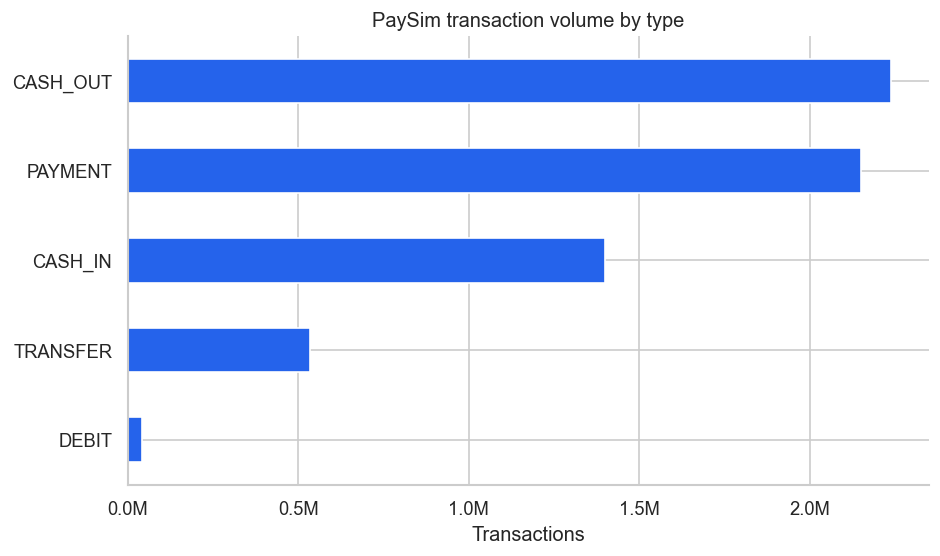

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.8))
type_fraud["total"].sort_values().plot.barh(ax=ax, color="#2563EB")
ax.set(title="PaySim transaction volume by type", xlabel="Transactions", ylabel="")
ax.xaxis.set_major_formatter(lambda value, _: f"{value/1_000_000:.1f}M")
sns.despine()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_transaction_type_distribution.png", bbox_inches="tight")
plt.show()

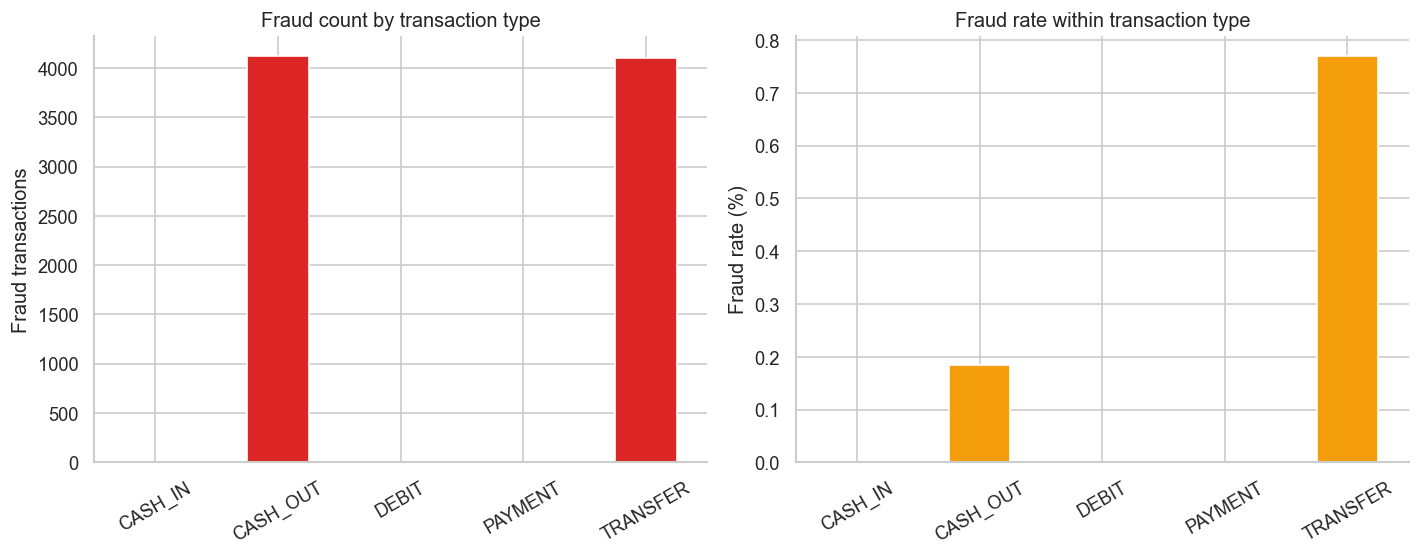

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
type_fraud["fraud"].plot.bar(ax=axes[0], color="#DC2626")
type_fraud["fraud_rate_pct"].plot.bar(ax=axes[1], color="#F59E0B")
axes[0].set(title="Fraud count by transaction type", xlabel="", ylabel="Fraud transactions")
axes[1].set(title="Fraud rate within transaction type", xlabel="", ylabel="Fraud rate (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
sns.despine()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_fraud_by_transaction_type.png", bbox_inches="tight")
plt.show()

## 6. Transaction amounts

,minimum,maximum,median,mean
legitimate,0.01,"92,445,516.64","74,684.72","178,197.04"
fraud,0.00,"10,000,000.00","441,423.44","1,467,967.30"


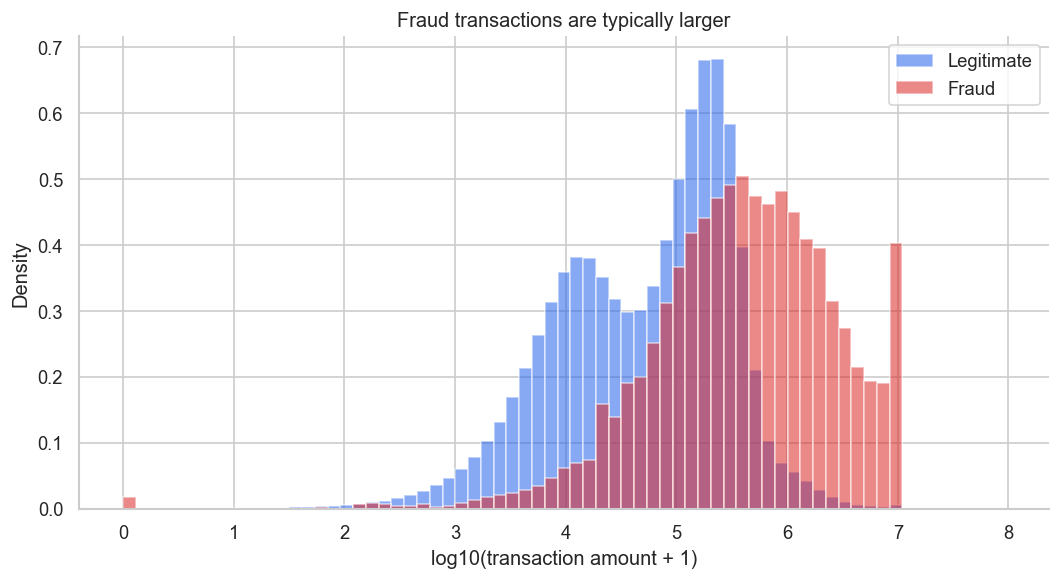

In [7]:
amount_values = {label: np.concatenate(parts) for label, parts in amount_parts.items()}
amount_summary = pd.DataFrame({
    label: {
        "minimum": values.min(),
        "maximum": values.max(),
        "median": np.median(values),
        "mean": values.mean(),
    }
    for label, values in amount_values.items()
}).rename(columns={0: "legitimate", 1: "fraud"}).T
display(amount_summary.style.format("{:,.2f}"))

bins = np.linspace(0, np.log10(max(values.max() for values in amount_values.values()) + 1), 70)
fig, ax = plt.subplots(figsize=(9, 5))
for label, color in [(0, "#2563EB"), (1, "#DC2626")]:
    ax.hist(
        np.log10(amount_values[label] + 1), bins=bins, density=True, alpha=0.55,
        label="Legitimate" if label == 0 else "Fraud", color=color,
    )
ax.set(title="Fraud transactions are typically larger", xlabel="log10(transaction amount + 1)", ylabel="Density")
ax.legend()
sns.despine()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_amount_distribution_by_fraud.png", bbox_inches="tight")
plt.show()

## 7. Time distribution and simulation artifact

minimum_step           1.000000
maximum_step         743.000000
maximum_step_days     30.958333
dtype: float64

,transactions,fraud,fraud_rate_pct
simulated_day,,,
1,574255,271,0.047192
2,455238,309,0.067877
3,1070,310,28.971963
4,28240,262,0.927762
5,9789,252,2.574318
6,441005,228,0.051700
7,420583,272,0.064672
8,449637,278,0.061828
9,417919,255,0.061017


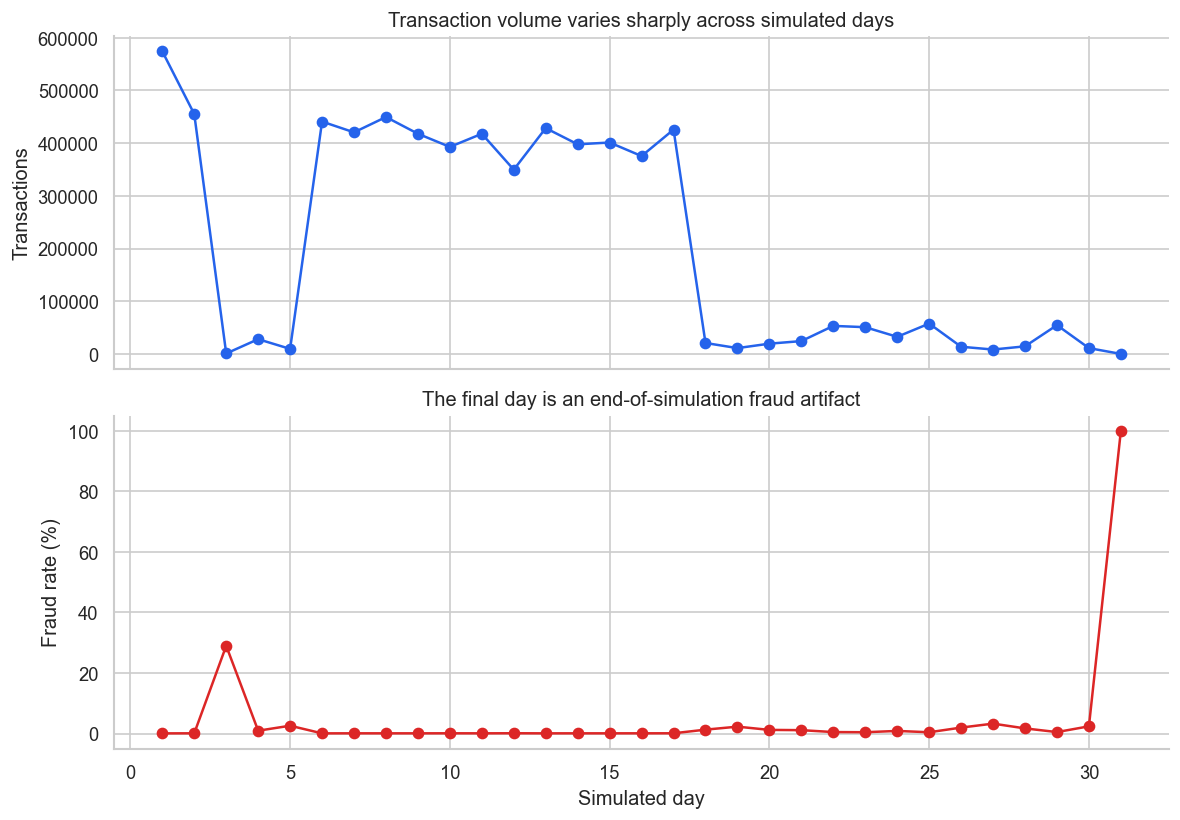

In [8]:
days = sorted(daily_totals)
daily = pd.DataFrame({
    "transactions": [daily_totals[day] for day in days],
    "fraud": [daily_fraud[day] for day in days],
}, index=pd.Index(days, name="simulated_day"))
daily["fraud_rate_pct"] = daily["fraud"] / daily["transactions"] * 100
display(pd.Series({"minimum_step": step_min, "maximum_step": step_max, "maximum_step_days": step_max / 24}))
display(daily)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
daily["transactions"].plot(ax=axes[0], marker="o", color="#2563EB")
daily["fraud_rate_pct"].plot(ax=axes[1], marker="o", color="#DC2626")
axes[0].set(title="Transaction volume varies sharply across simulated days", ylabel="Transactions")
axes[1].set(title="The final day is an end-of-simulation fraud artifact", xlabel="Simulated day", ylabel="Fraud rate (%)")
sns.despine()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_daily_volume_and_fraud_rate.png", bbox_inches="tight")
plt.show()

## 8. Identifier behaviour

Exact identifier frequencies require retaining one identifier column at a time. Each column is released before the next is read.

In [9]:
identifier_rows = []
for column in ("nameOrig", "nameDest"):
    identifiers = pd.read_csv(CSV_PATH, usecols=[column])[column]
    counts = identifiers.value_counts()
    identifier_rows.append({
        "column": column,
        "unique_identifiers": counts.size,
        "single_use_identifiers": int(counts.eq(1).sum()),
        "repeated_identifiers": int(counts.gt(1).sum()),
        "maximum_occurrences": int(counts.max()),
    })
    del identifiers, counts
identifier_summary = pd.DataFrame(identifier_rows).set_index("column")
prefix_summary = pd.DataFrame({
    "nameOrig": pd.Series(origin_prefixes),
    "nameDest": pd.Series(destination_prefixes),
}).fillna(0).astype(int)
display(identifier_summary)
display(prefix_summary)

,unique_identifiers,single_use_identifiers,repeated_identifiers,maximum_occurrences
column,,,,
nameOrig,6353307,6344009,9298,3
nameDest,2722362,2262704,459658,113


,nameOrig,nameDest
C,6362620,4211125
M,0,2151495


## 9. Balance leakage demonstration — analysis only

> **PROHIBITED FOR PREDICTION:** The four raw balance columns and every discrepancy or zero-balance feature derived from them are analysed only to show why the official warning matters. They must not be used as predictive features.

,label,column,zero_count,zero_pct
0,legitimate,oldbalanceOrg,2102408,33.085825
1,legitimate,newbalanceOrig,3601513,56.677405
2,legitimate,oldbalanceDest,2699037,42.475041
3,legitimate,newbalanceDest,2435342,38.325244
4,fraud,oldbalanceOrg,41,0.499209
5,fraud,newbalanceOrig,8053,98.051869
6,fraud,oldbalanceDest,5351,65.152807
7,fraud,newbalanceDest,4091,49.811275


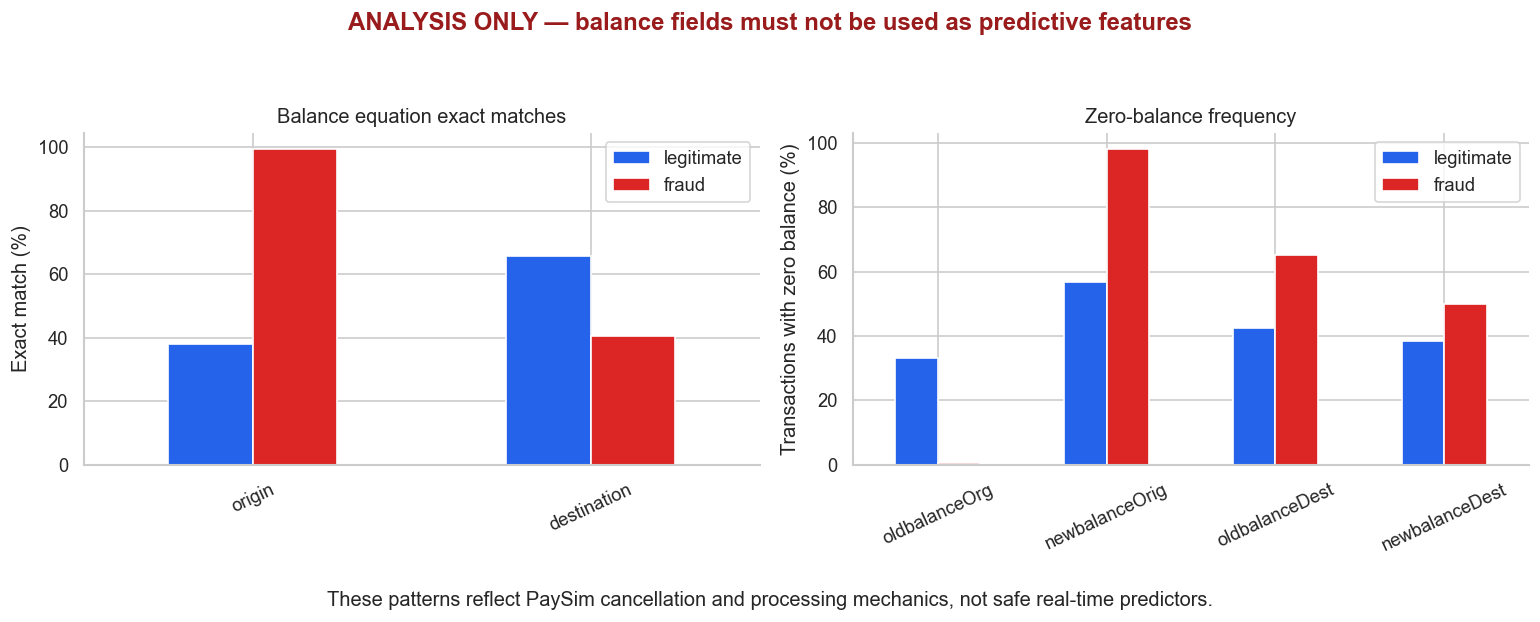

In [10]:
def discrepancy_summary(parts):
    values = np.concatenate(parts)
    return {
        "transactions": values.size,
        "exact_match_pct": (values == 0).mean() * 100,
        "mean_abs_discrepancy": values.mean(),
        "median_abs_discrepancy": np.median(values),
        "p95_abs_discrepancy": np.percentile(values, 95),
        "maximum_abs_discrepancy": values.max(),
    }

balance_summary_rows = []
for balance_side, groups in [("origin", origin_discrepancy_parts), ("destination", destination_discrepancy_parts)]:
    for label in (0, 1):
        balance_summary_rows.append({
            "balance_side": balance_side,
            "label": "legitimate" if label == 0 else "fraud",
            **discrepancy_summary(groups[label]),
        })
balance_summary = pd.DataFrame(balance_summary_rows).set_index(["balance_side", "label"])

label_totals = {0: type_fraud["legitimate"].sum(), 1: type_fraud["fraud"].sum()}
zero_rows = []
for label in (0, 1):
    for column in ANALYSIS_ONLY_BALANCE_COLUMNS:
        zero_rows.append({
            "label": "legitimate" if label == 0 else "fraud",
            "column": column,
            "zero_count": zero_balances[(label, column)],
            "zero_pct": zero_balances[(label, column)] / label_totals[label] * 100,
        })
zero_summary = pd.DataFrame(zero_rows)
display(balance_summary.style.format("{:,.2f}"))
display(zero_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
exact_matches = balance_summary["exact_match_pct"].unstack("label")[["legitimate", "fraud"]].reindex(["origin", "destination"])
exact_matches.plot.bar(ax=axes[0], color=["#2563EB", "#DC2626"])
zero_plot = zero_summary.pivot(index="column", columns="label", values="zero_pct")[["legitimate", "fraud"]].reindex(ANALYSIS_ONLY_BALANCE_COLUMNS)
zero_plot.plot.bar(ax=axes[1], color=["#2563EB", "#DC2626"])
axes[0].set(title="Balance equation exact matches", xlabel="", ylabel="Exact match (%)")
axes[1].set(title="Zero-balance frequency", xlabel="", ylabel="Transactions with zero balance (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.legend(title="")
fig.suptitle("ANALYSIS ONLY — balance fields must not be used as predictive features", color="#991B1B", weight="bold")
fig.text(0.5, -0.01, "These patterns reflect PaySim cancellation and processing mechanics, not safe real-time predictors.", ha="center")
sns.despine()
fig.tight_layout(rect=[0, 0.04, 1, 0.93])
fig.savefig(FIGURES_DIR / "05_balance_leakage_evidence.png", bbox_inches="tight")
plt.show()

## 10. Conclusions and modelling constraints

### Official facts
- PaySim is synthetic, one step is one hour, and detected fraud transactions are cancelled.
- The official documentation prohibits using all four balance fields for fraud detection.

### Findings from this CSV
- The data contains 6,362,620 transactions and 8,213 fraud labels (0.1291%).
- Fraud occurs only in `TRANSFER` and `CASH_OUT`.
- The final simulated day and the balance relationships contain strong artifacts.

### Constraints for later modelling
- Do not use raw or derived balance features, `isFlaggedFraud`, or raw identifiers.
- Treat `step` carefully and prefer chronological validation.
- Use imbalanced-data metrics rather than accuracy alone.

No modelling is performed in this notebook.